# 01 · Data: 1-minute windows of the WESAD wrist (E4) EDA

**Data.** WESAD, wrist **Empatica E4 EDA (4 Hz)**, taken from the `signal/wrist/EDA` channel of each `S*.pkl`.
This is the E4 stream synchronised with the study labels; see `code_draft/read_E4_EDA.ipynb`.
`Data/wesad_eda/wesad_subject_list.pkl` (made by `code_draft/01load_eda.ipynb`) holds, for each of the
15 subjects, the raw EDA (µS) and the 4 Hz label (mode of the 700 Hz label).

**Windows.** 60 s (240 samples), slid with a 10 s stride. A window is kept only when it lies *entirely* inside
one condition block (100 % label purity). Labels: 1 = baseline, 2 = stress.

Output (in `code_draft2/cache/`): `windows_stride10.npz` + `windows_meta_stride10.csv` (baseline & stress).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from eda_utils import *

STRIDE = 10   # seconds between consecutive window starts
CACHE.mkdir(exist_ok=True)

## Load the E4 EDA of the 15 subjects

In [2]:
subjects = load_subjects()
summary = pd.DataFrame({sid: {"minutes": len(e) / FS / 60,
                              "baseline_min": (l == 1).sum() / FS / 60,
                              "stress_min": (l == 2).sum() / FS / 60,
                              "amusement_min": (l == 3).sum() / FS / 60,
                              "EDA_median_uS": np.median(e)}
                        for sid, (e, l) in subjects.items()}).T.round(2)
summary

,minutes,baseline_min,stress_min,amusement_min,EDA_median_uS
S2,101.32,19.07,10.25,6.03,0.24
S3,108.22,19.00,10.67,6.25,0.47
S4,107.05,19.30,10.58,6.20,0.18
S5,104.30,19.97,10.75,6.23,1.23
S6,117.85,19.67,10.83,6.20,2.49
S7,87.30,19.77,10.67,6.20,4.70
S8,91.10,19.48,11.17,6.17,0.29
S9,87.05,19.67,10.75,6.20,0.45
S10,91.60,19.67,12.08,6.20,0.47
S11,87.22,19.67,11.33,6.13,2.91


Raw EDA level differs by more than an order of magnitude between subjects (e.g. S2 vs S13). Notebook 02 works without
per-subject normalisation and tests whether the `gmsEDA` decomposition helps.

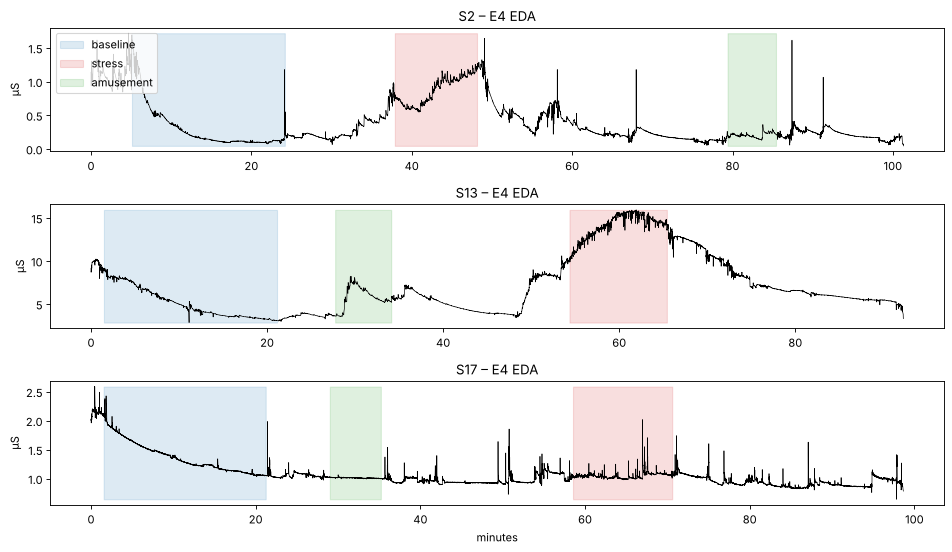

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7))
for ax, sid in zip(axes, ["S2", "S13", "S17"]):
    e, l = subjects[sid]
    t = np.arange(len(e)) / FS / 60
    ax.plot(t, e, lw=0.6, color="k")
    for c, col in [(1, "tab:blue"), (2, "tab:red"), (3, "tab:green")]:
        ax.fill_between(t, e.min(), e.max(), where=l == c, color=col, alpha=0.15,
                        label={1: "baseline", 2: "stress", 3: "amusement"}[c])
    ax.set_title(f"{sid} – E4 EDA"); ax.set_ylabel("µS")
axes[0].legend(loc="upper left"); axes[-1].set_xlabel("minutes")
plt.tight_layout(); plt.show()

## Cut 1-minute windows

In [4]:
W, meta = make_windows(subjects, labels=(1, 2), stride_sec=STRIDE)
np.savez_compressed(CACHE / f"windows_stride{STRIDE}.npz", W=W)
meta.to_csv(CACHE / f"windows_meta_stride{STRIDE}.csv", index=False)
print("baseline/stress windows:", W.shape)
print(meta.groupby(["subject", "label"]).size().unstack().T.to_string())

baseline/stress windows: (2599, 240)
subject  S10  S11  S13  S14  S15  S16  S17   S2   S3   S4   S5   S6   S7   S8   S9
label                                                                             
1        113  113  113  113  112  113  113  109  109  110  114  113  113  111  113
2         67   63   61   62   63   62   67   56   59   58   59   60   59   62   59
